In [1]:
# Import libraries
import pandas as pd
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

In [2]:
# Read data - white wine
df_whiteWine = pd.read_csv("winequality-white.csv", delimiter=';')
df_whiteWine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [3]:
# Read data - red wine
df_redWine = pd.read_csv("winequality-red.csv", delimiter=';')
df_redWine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


### Common functions applicable to both datasets

In [4]:
# Data pre-processing: Write code
def data_standard_scaling(df):
    scaler = StandardScaler();
    Data_scaled = scaler.fit_transform(df) # All the 12 columns are numerical

    data_df_scaled = pd.DataFrame(Data_scaled, columns=df.columns) # Convert NumPy array to Dataframe
    return data_df_scaled

In [5]:
# Side by side comparison of both data (scaled data vs unprocessed)
def data_comparison(data, scaled_data):
    comparison = pd.concat(
        {
            'Scaled': scaled_data.head(),
            'Original': data.head()
        },
        axis=1
    )

    comparison = comparison.swaplevel(axis=1)
    display(comparison.reindex(columns=data.columns, level=0))

In [6]:
# Apply K-Means Clustering: Write code
def apply_k_means(scaled_df):
    k_values = []
    inertia = []
    
    for k in range(1, 11):
        kmeans = KMeans(
            n_clusters=k,
            init='k-means++',
            n_init=10, # sets the number of time the algorithm runs with different centroid seeds
            random_state=42
        )
        kmeans.fit(scaled_df)
        k_values.append(k)
        inertia.append(kmeans.inertia_)

    return k_values, inertia

In [7]:
# Apply Hierarchical (agglomerative) Clustering: Write code
def apply_hierarchical_agglomerative(scaled_df):

    # Calculate the silhouette_score for AgglomerativeClustering
    k_values = []
    coeff_values = []

    for k in range(2,10):
        ac = AgglomerativeClustering(n_clusters = k)
        ac.fit(scaled_df)
        k_values.append(k)
        coeff_values.append(silhouette_score(scaled_df, ac.labels_))
    return k_values, coeff_values

In [8]:
# Finding optimal k using Elbow Method: Write code

def plot_k_mean(plot_title, k_values, inertia):

    # Plot the result
    plt.plot(k_values, inertia, marker='o')
    plt.scatter(k_values, inertia)
    plt.xlabel('Number of Clusters')
    plt.ylabel('inertia')
    plt.title(f'Elbow Method for Optimal k - {plot_title}')
    plt.show()

In [9]:
def plot_agglomerative_clusters_pca(plot_title, scaled_df, clustersNo):
    
    agglomerative_model = AgglomerativeClustering(n_clusters=clustersNo)
    labels = agglomerative_model.fit_predict(scaled_df)

    # Reduce the data to two components for visualisation
    pca = PCA(n_components=2)
    data_pca = pca.fit_transform(scaled_df)

    plt.figure(figsize=(7, 5))
    sns.scatterplot(
        x=data_pca[:, 0],
        y=data_pca[:, 1],
        hue=labels.astype(str),
        palette='colorblind',
        s=25,
        edgecolor='white',
        linewidth=0.5,
        legend='full'
    )
    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')
    plt.title(f'Hierarchical (Agglomerative) Clustering (k = {clustersNo}) on {plot_title}')
    plt.legend(title='Cluster')
    plt.show()

In [10]:
# Visualizing Clusters using PCA: Write code
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

def plot_kmeans_clusters_pca(plot_title, scaled_df, clustersNo):

    kmeans_optimal = KMeans(
        n_clusters=clustersNo,
        init='k-means++',
        n_init=10,
        random_state=42
    )

    labels = kmeans_optimal.fit_predict(scaled_df)

    # Reduce the data to two components for visualisation
    pca = PCA(n_components=2)
    data_pca = pca.fit_transform(scaled_df)

    plt.figure(figsize=(7, 5))
    sns.scatterplot(
        x=data_pca[:, 0],
        y=data_pca[:, 1],
        hue=labels.astype(str),
        palette='colorblind',
        s=25,
        edgecolor='white',
        linewidth=0.5,
        legend='full'
    )
    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')
    plt.title(f'K-Means Clusters (k = {clustersNo}) on {plot_title}')
    plt.legend(title='Cluster')
    plt.show()

In [11]:
# Visualizing Hierarchical Clusters using Dendogram
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

def plot_dendrogram(plot_title, scaled_df):
    linked = linkage(scaled_df, method='ward') # Ward’s method decides which clusters to merge during hierarchical clustering.

    plt.figure(figsize=(12, 6))
    dendrogram(
        linked,
        no_labels=True,
        above_threshold_color='steelblue'
    )
    plt.title(f'Hierarchical Clustering Dendrogram — {plot_title}')
    plt.xlabel('Samples')
    plt.ylabel('Merge Distance')
    plt.tight_layout()
    plt.show()

In [12]:
def add_cluster_labels(original_df, scaled_df, kmeans_k, hierarchical_k):
    result = original_df.copy()

    kmeans = KMeans(
        n_clusters=kmeans_k,
        init='k-means++',
        n_init=10,
        random_state=42
    )
    result['KMeans_Cluster'] = kmeans.fit_predict(scaled_df)

    hierarchical = AgglomerativeClustering(
        n_clusters=hierarchical_k
    )
    result['Hierarchical_Cluster'] = hierarchical.fit_predict(scaled_df)

    return result

### Data pre-processing
HINT: Scale numerical values using *StandardScaler*

### White Wine

In [13]:
whiteWine_df_scaled = data_standard_scaling(df_whiteWine)
whiteWine_df_scaled.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,0.172097,-0.081770,0.213280,2.821349,-0.035355,0.569932,0.744565,2.331512,-1.246921,-0.349184,-1.393152,0.13787
1,-0.657501,0.215896,0.048001,-0.944765,0.147747,-1.253019,-0.149685,-0.009154,0.740029,0.001342,-0.824276,0.13787
2,1.475751,0.017452,0.543838,0.100282,0.193523,-0.312141,-0.973336,0.358665,0.475102,-0.436816,-0.336667,0.13787
3,0.409125,-0.478657,-0.117278,0.415768,0.559727,0.687541,1.121091,0.525855,0.011480,-0.787342,-0.499203,0.13787
4,0.409125,-0.478657,-0.117278,0.415768,0.559727,0.687541,1.121091,0.525855,0.011480,-0.787342,-0.499203,0.13787


In [14]:
data_comparison(df_whiteWine, whiteWine_df_scaled)


fixed acidity          volatile acidity          citric acid           \
         Scaled Original           Scaled Original      Scaled Original   
0      0.172097      7.0        -0.081770     0.27    0.213280     0.36   
1     -0.657501      6.3         0.215896     0.30    0.048001     0.34   
2      1.475751      8.1         0.017452     0.28    0.543838     0.40   
3      0.409125      7.2        -0.478657     0.23   -0.117278     0.32   
4      0.409125      7.2        -0.478657     0.23   -0.117278     0.32   

  residual sugar          chlorides           ...   density           \
          Scaled Original    Scaled Original  ...    Scaled Original   
0       2.821349     20.7 -0.035355    0.045  ...  2.331512   1.0010   
1      -0.944765      1.6  0.147747    0.049  ... -0.009154   0.9940   
2       0.100282      6.9  0.193523    0.050  ...  0.358665   0.9951   
3       0.415768      8.5  0.559727    0.058  ...  0.525855   0.9956   
4       0.415768      8.5  0.559727    0.058  ...  0.525855   0.9956   

         pH          sulphates            alcohol           quality           
     Scaled Original    Scaled Original    Scaled Original   Scaled Original  
0 -1.246921     3.00 -0.349184     0.45 -1.393152      8.8  0.13787        6  
1  0.740029     3.30  0.001342     0.49 -0.824276      9.5  0.13787        6  
2  0.475102     3.26 -0.436816     0.44 -0.336667     10.1  0.13787        6  
3  0.011480     3.19 -0.787342     0.40 -0.499203      9.9  0.13787        6  
4  0.011480     3.19 -0.787342     0.40 -0.499203      9.9  0.13787        6  

[5 rows x 24 columns]

### Red Wine

In [15]:
redWine_df_scaled = data_standard_scaling(df_redWine)
redWine_df_scaled.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,-0.528360,0.961877,-1.391472,-0.453218,-0.243707,-0.466193,-0.379133,0.558274,1.288643,-0.579207,-0.960246,-0.787823
1,-0.298547,1.967442,-1.391472,0.043416,0.223875,0.872638,0.624363,0.028261,-0.719933,0.128950,-0.584777,-0.787823
2,-0.298547,1.297065,-1.186070,-0.169427,0.096353,-0.083669,0.229047,0.134264,-0.331177,-0.048089,-0.584777,-0.787823
3,1.654856,-1.384443,1.484154,-0.453218,-0.264960,0.107592,0.411500,0.664277,-0.979104,-0.461180,-0.584777,0.450848
4,-0.528360,0.961877,-1.391472,-0.453218,-0.243707,-0.466193,-0.379133,0.558274,1.288643,-0.579207,-0.960246,-0.787823


In [16]:
data_comparison(df_redWine, redWine_df_scaled)

fixed acidity          volatile acidity          citric acid           \
         Scaled Original           Scaled Original      Scaled Original   
0     -0.528360      7.4         0.961877     0.70   -1.391472     0.00   
1     -0.298547      7.8         1.967442     0.88   -1.391472     0.00   
2     -0.298547      7.8         1.297065     0.76   -1.186070     0.04   
3      1.654856     11.2        -1.384443     0.28    1.484154     0.56   
4     -0.528360      7.4         0.961877     0.70   -1.391472     0.00   

  residual sugar          chlorides           ...   density           \
          Scaled Original    Scaled Original  ...    Scaled Original   
0      -0.453218      1.9 -0.243707    0.076  ...  0.558274   0.9978   
1       0.043416      2.6  0.223875    0.098  ...  0.028261   0.9968   
2      -0.169427      2.3  0.096353    0.092  ...  0.134264   0.9970   
3      -0.453218      1.9 -0.264960    0.075  ...  0.664277   0.9980   
4      -0.453218      1.9 -0.243707    0.076  ...  0.558274   0.9978   

         pH          sulphates            alcohol            quality           
     Scaled Original    Scaled Original    Scaled Original    Scaled Original  
0  1.288643     3.51 -0.579207     0.56 -0.960246      9.4 -0.787823        5  
1 -0.719933     3.20  0.128950     0.68 -0.584777      9.8 -0.787823        5  
2 -0.331177     3.26 -0.048089     0.65 -0.584777      9.8 -0.787823        5  
3 -0.979104     3.16 -0.461180     0.58 -0.584777      9.8  0.450848        6  
4  1.288643     3.51 -0.579207     0.56 -0.960246      9.4 -0.787823        5  

[5 rows x 24 columns]

Explain what is changed.

**Mohammed Grech 12/10/2026:** After using StandardScaler, all 12 numerical features (on both dataset) are on a comparable scale, with a mean close to 0 and a standard deviation close to 1. Positive values are above the feature’s original average, while negative values are below it. Values can still be greater than 1 or less than −1 because they show how many standard deviations away from the average they are. This helps give the features a more balanced influence when clustering the data.

### Apply K-Means and Hierarchical (agglomerative) Clustering
Note: Apply two approaches on both winequality-white.csv and winequality-red.csv

### White Wine

In [17]:
# Apply K-Means Clustering: 
white_k_values, white_inertia = apply_k_means(whiteWine_df_scaled)

# Apply Hierarchical (agglomerative)
white_k_values_agglomerative, white_coeff_values = apply_hierarchical_agglomerative(whiteWine_df_scaled)

### Red Wine

In [18]:
# Apply K-Means Clustering: 
red_k_values, red_inertia = apply_k_means(redWine_df_scaled)

# Apply Hierarchical (agglomerative)
red_k_values_agglomerative, red_coeff_values = apply_hierarchical_agglomerative(redWine_df_scaled)

### Visualizing Clusters: KMeans

Principal Component Analysis (PCA) is a powerful dimensionality reduction technique used in machine learning and data analysis to simplify complex datasets while preserving as much important information as possible. It works by transforming the original high-dimensional data into a new coordinate system where the axes (called principal components) capture the directions of maximum variance in the data. The first principal component accounts for the most variance, followed by the second, and so on. When visualizing high-dimensional data, PCA is particularly useful as it allows us to project the data into just two components (PCA1 and PCA2), enabling a meaningful 2D representation of the dataset. This transformation helps in clustering, classification, and pattern recognition by revealing inherent structures within the data. In clustering tasks like K-Means and Hierarchical Clustering, PCA aids in visualization by reducing noise and allowing us to plot the clusters effectively, making it easier to interpret patterns and relationships within the dataset.

HINT: Use Principal Component Analysis (PCA) to reduce high-dimensional data to 2 components. Use *seaborn.scatterplot*

### White Wine

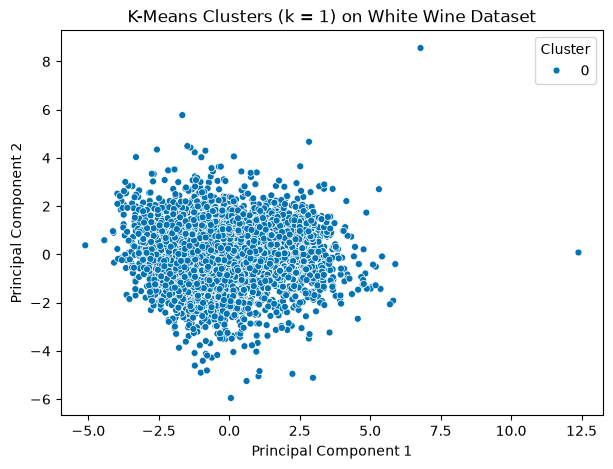

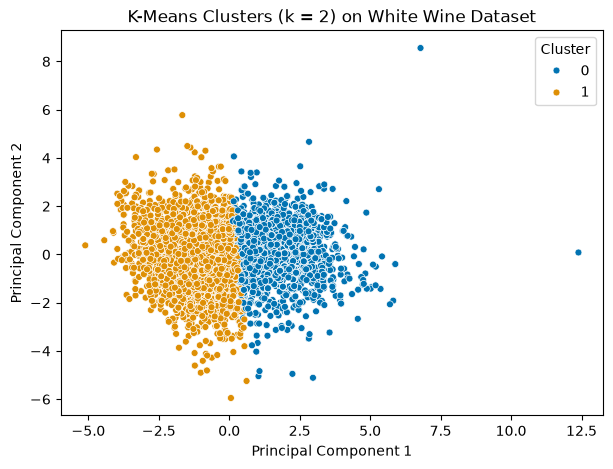

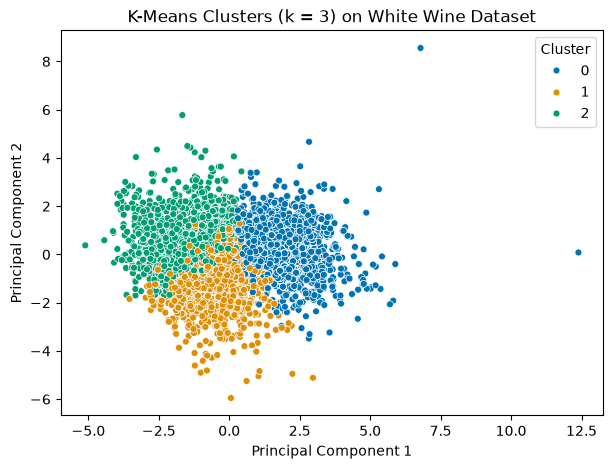

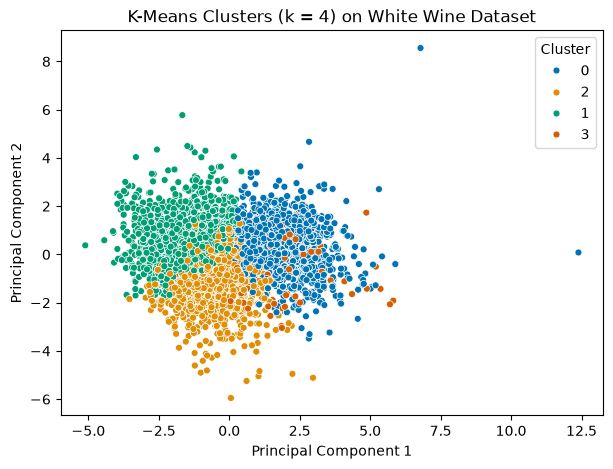

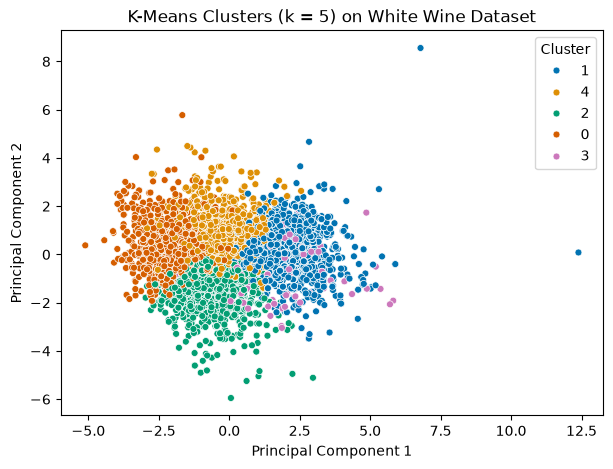

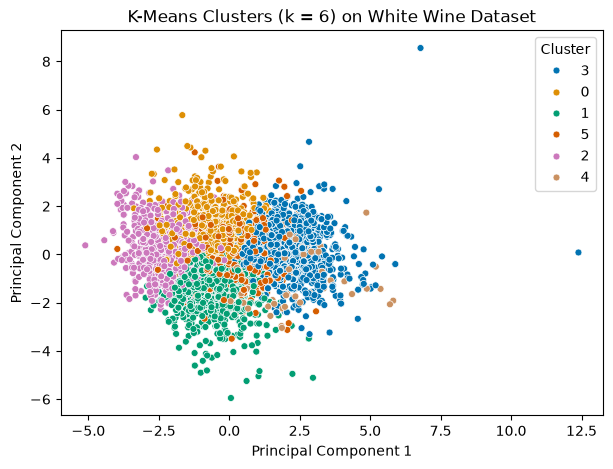

In [19]:
for k in range(1, 7):
    plot_kmeans_clusters_pca('White Wine Dataset', whiteWine_df_scaled, k)

### Red Wine

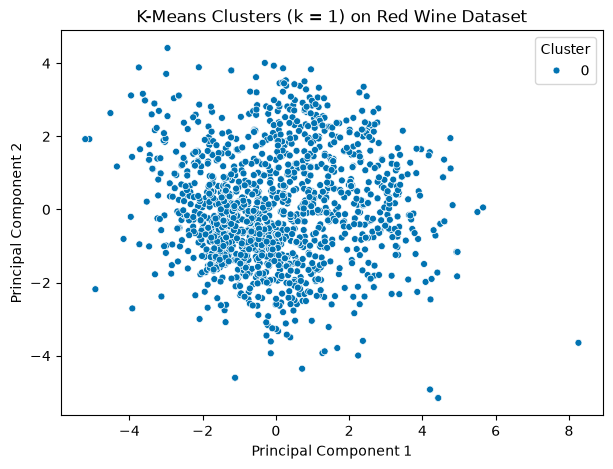

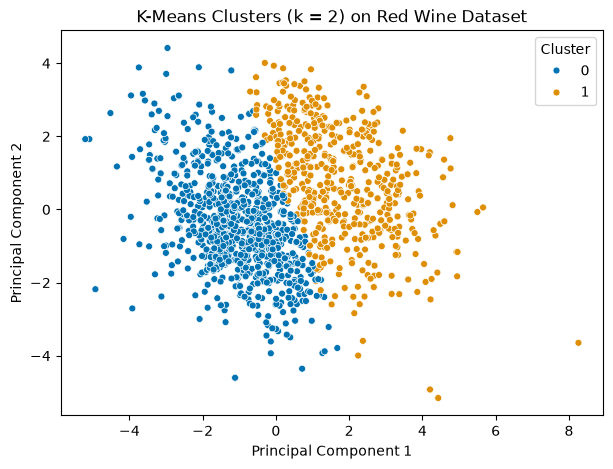

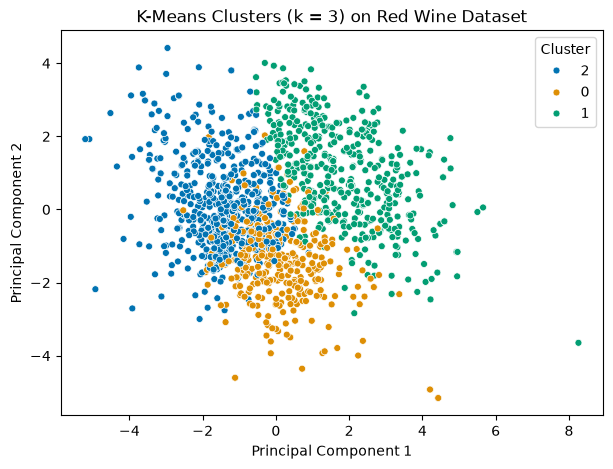

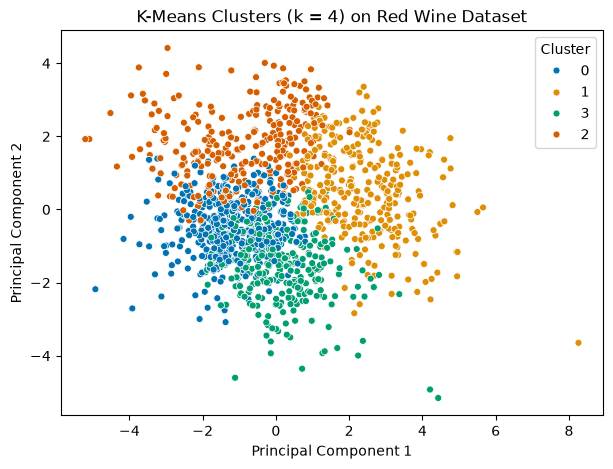

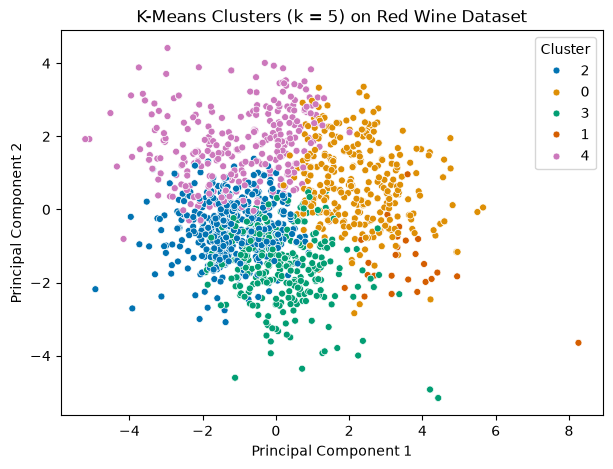

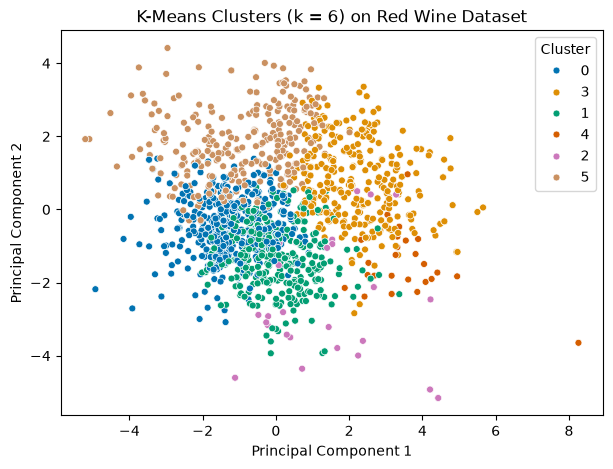

In [20]:
for k in range(1, 7):
    plot_kmeans_clusters_pca('Red Wine Dataset', redWine_df_scaled, k)

**Mohammed Grech**: Based on the PCA plots, two clusters appear to provide a reasonable grouping of the data, although there is no clear separation between them. Adding more clusters splits the data into smaller groups without making them clearly distinct, so there is little visual evidence to support a higher k.

### Optimal _k_
Find the optimal number of clusters (k) using the Elbow Method.

Inertia, also known as the Within-Cluster Sum of Squares (WCSS), is a key metric used in K-Means clustering to measure how well data points are assigned to their respective clusters. It is calculated as the sum of the squared distances between each data point and the centroid of its assigned cluster.  A lower inertia value indicates that data points are closely packed around their centroids, signifying well-formed clusters.

To determine the optimal number of clusters (k), the Elbow Method is commonly used, which involves plotting inertia values for different values of k and identifying the "elbow point" - the location where the rate of decrease sharply slows down, suggesting the best balance between compact clusters and overfitting. In Python, this can be easily computed using _kmeans.inertia__ from the _sklearn.cluster.KMeans_ module. By iterating over a range of k values and plotting their corresponding inertia scores, we can visualize the optimal number of clusters. The resulting Elbow Plot helps guide the selection of k by pinpointing where adding more clusters no longer significantly reduces inertia, ensuring a well-optimized clustering solution.

### White Wine

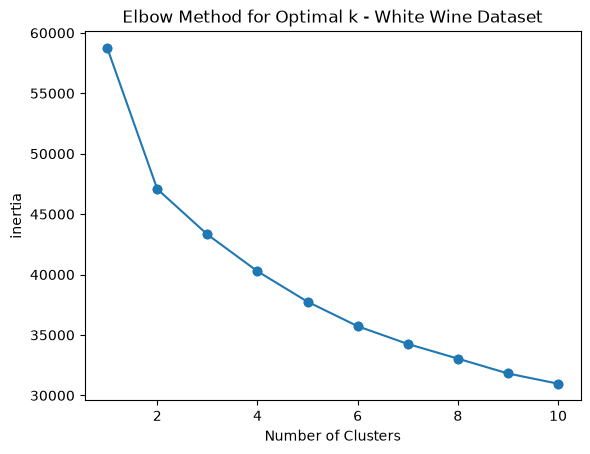

In [21]:
# Finding optimal k using Elbow Method: Write code
plot_k_mean('White Wine Dataset', white_k_values, white_inertia)

### Red Wine

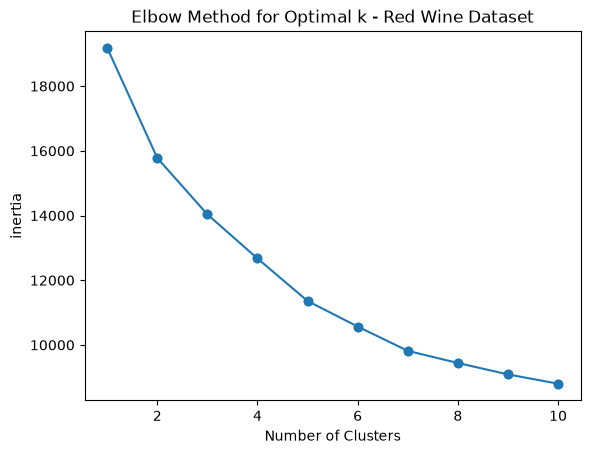

In [22]:
# Finding optimal k using Elbow Method: Write code
plot_k_mean('Red Wine Dataset', red_k_values, red_inertia)

**Mohammed Grech 15/10/2026**: Based on the elbow method for both datasets, k = 2 appears to be the most suitable choice, since further increases in k produce smaller and more gradual reductions in inertia.

### Visualizing Clusters: Agglomerative
 - Visualize using scatter plot - similar to KMeans
 - Generate a dendrogram to visualize hierarchical clustering.
 - Optimal k. Note: The **Silhouette Score** measures the cohesion and separation of clusters, helping determine the best k. A higher score indicates better clustering.

### White Wine

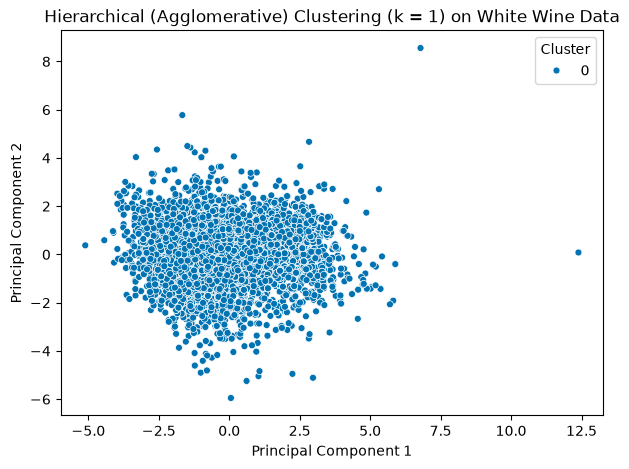

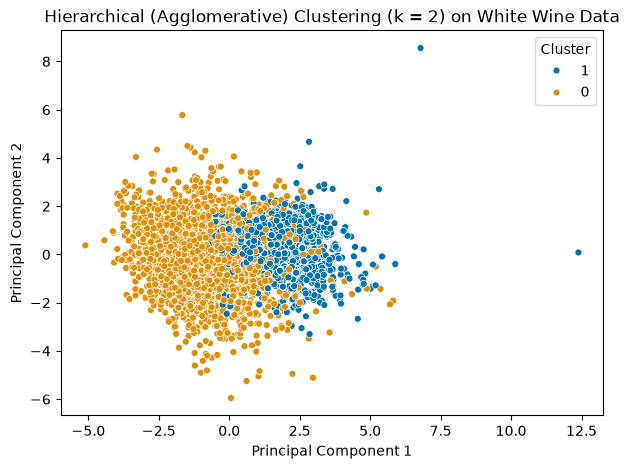

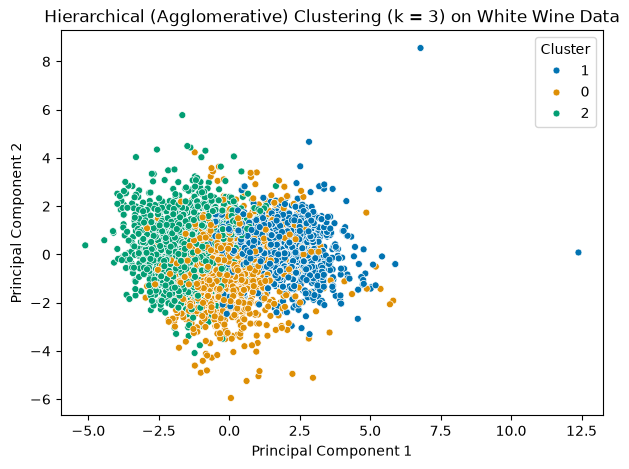

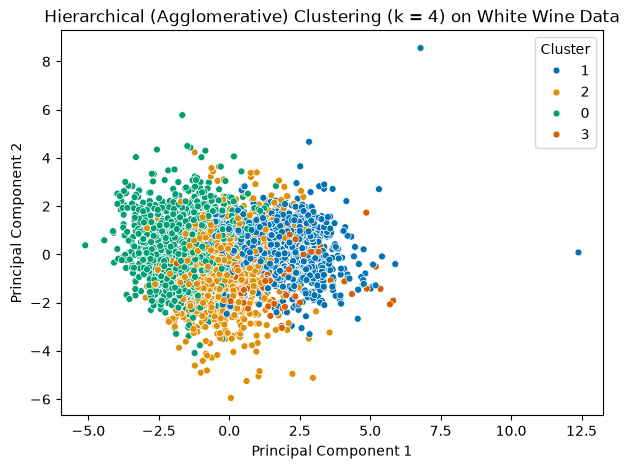

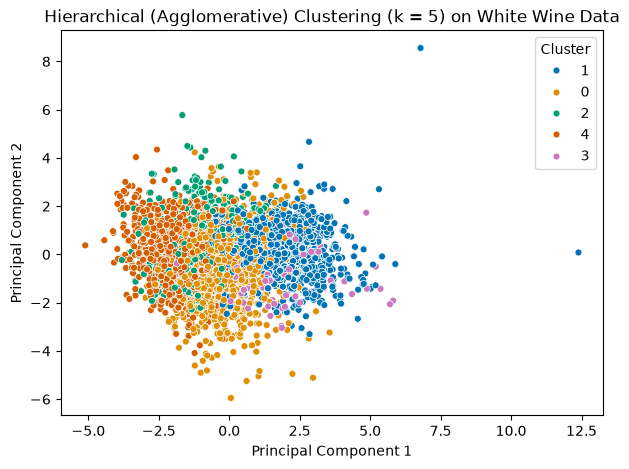

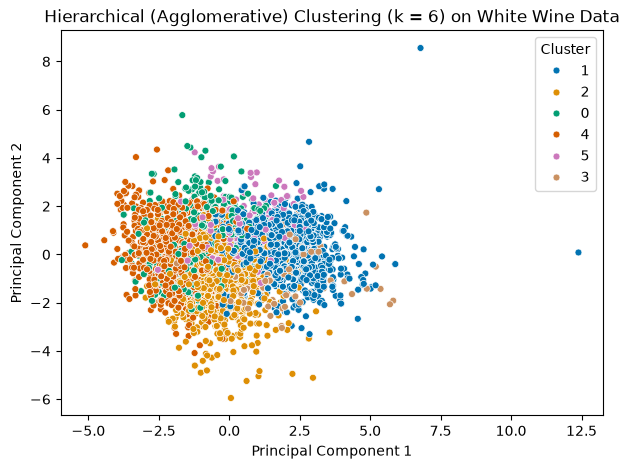

In [23]:
# Hierarchical Visualization: Write code
# Using different Ks to plot the results and visualise the difference between them.
for k in range(1, 7):
    plot_agglomerative_clusters_pca('White Wine Data', whiteWine_df_scaled, k)

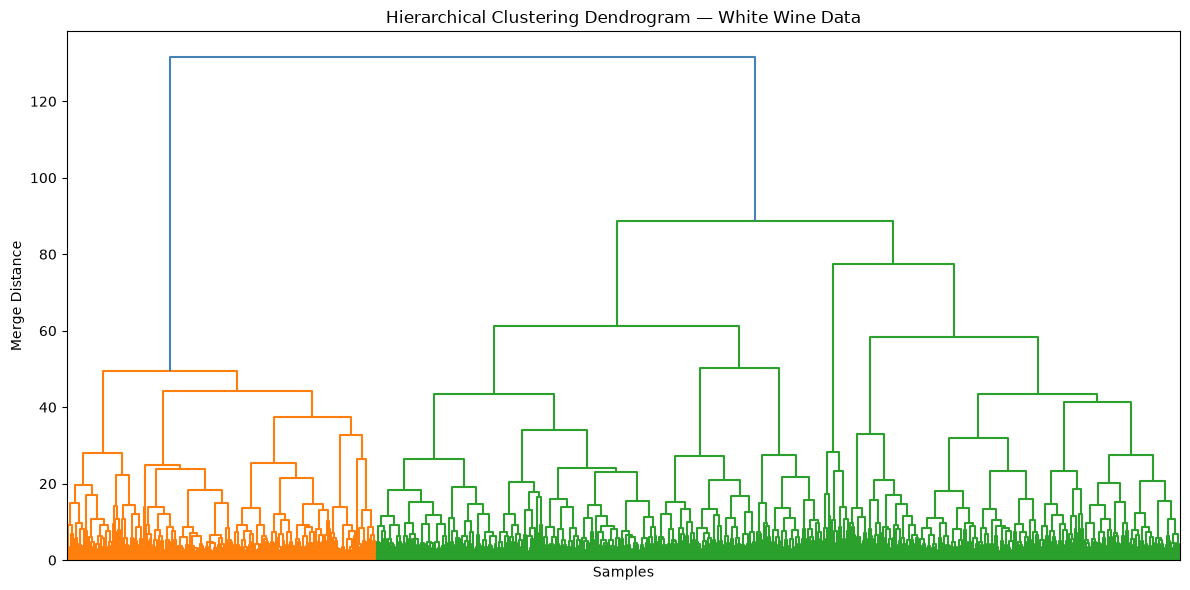

In [24]:
# Dendrogram for Hierarchical Clustering: Write code
plot_dendrogram('White Wine Data', whiteWine_df_scaled)

In [25]:
# Display the first few rows of the dataset with cluster labels
whiteWine_with_clusters = add_cluster_labels(
    df_whiteWine,
    whiteWine_df_scaled,
    kmeans_k=2, # Choosing K=2 here as it was inidcated as the optimal K  
    hierarchical_k=2
)

whiteWine_with_clusters.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,KMeans_Cluster,Hierarchical_Cluster
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6,0,1
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6,1,0
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6,1,0
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6,0,0
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6,0,0


### Red Wine

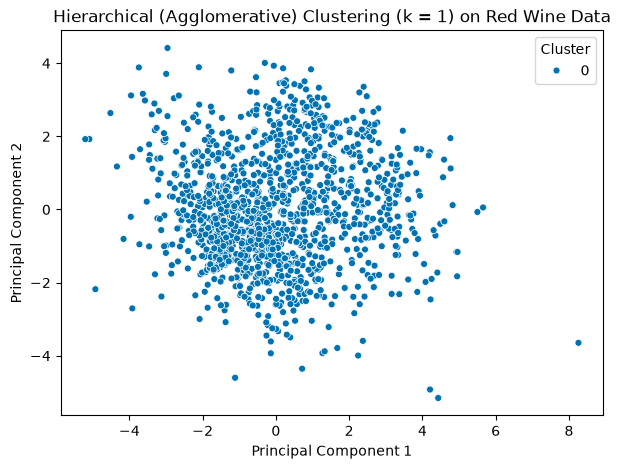

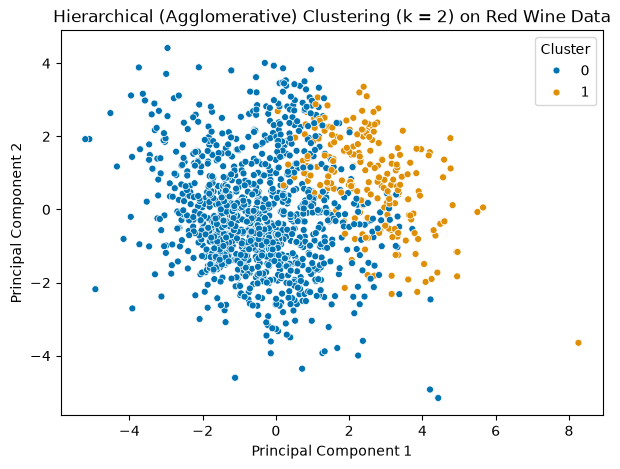

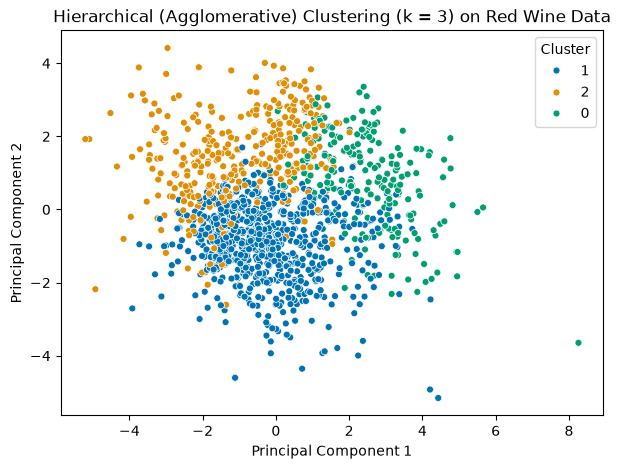

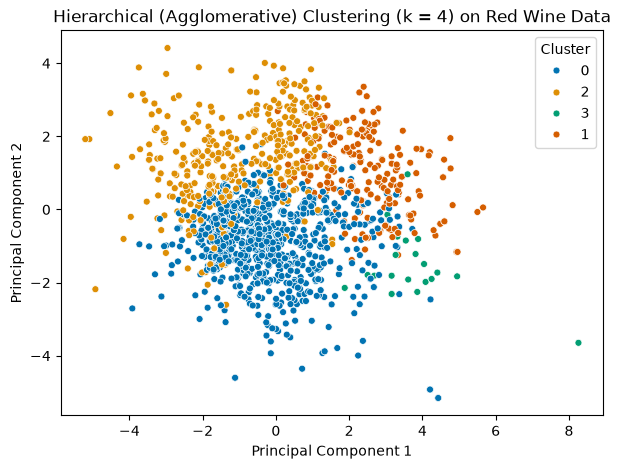

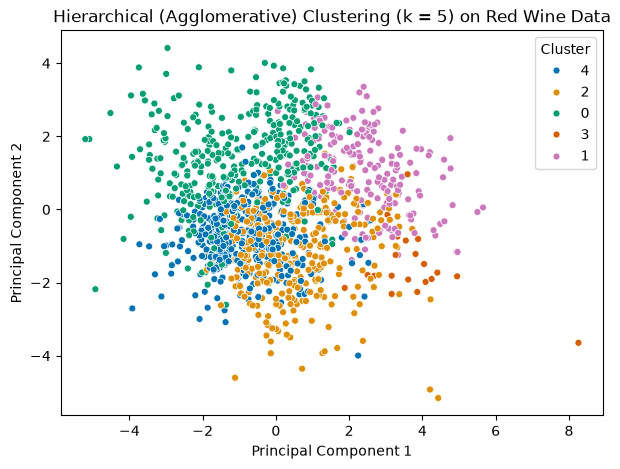

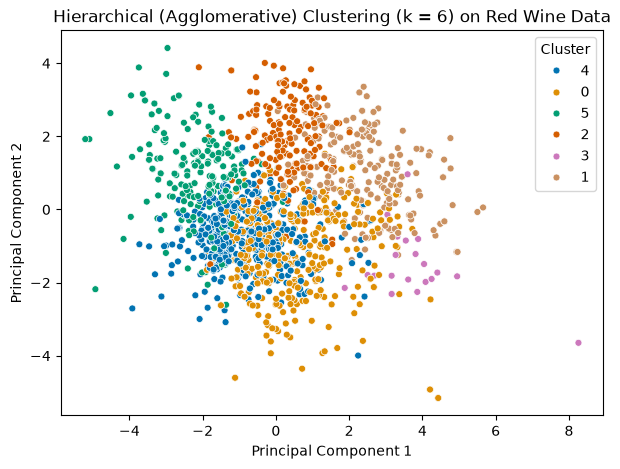

In [26]:
for k in range(1, 7):
    plot_agglomerative_clusters_pca('Red Wine Data', redWine_df_scaled, k)


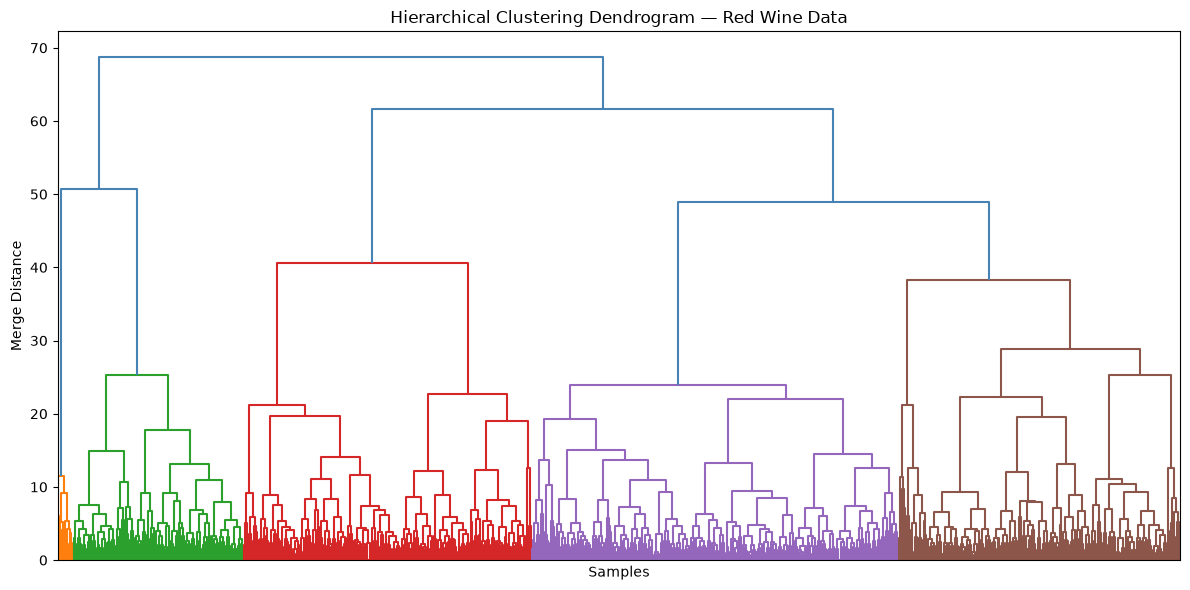

In [27]:
# Dendrogram for Hierarchical Clustering: Write code
plot_dendrogram('Red Wine Data', redWine_df_scaled)

In [28]:
# Display the first few rows of the dataset with cluster labels
redWine_with_clusters = add_cluster_labels(
    df_redWine,
    redWine_df_scaled,
    kmeans_k=2,
    hierarchical_k=2
)

redWine_with_clusters.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,KMeans_Cluster,Hierarchical_Cluster
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0,0


In [29]:
# Try different values of k and compute silhouette scores
def plot_silhouette_scores(plot_title, K, silhouette_scores):
    plt.figure(figsize=(8, 5))
    plt.plot(K, silhouette_scores, marker='o', linestyle='--')
    plt.xlabel('Number of Clusters (k)')
    plt.ylabel('Silhouette Score')
    plt.title(f'Optimal k using Silhouette Score — {plot_title}')
    plt.show()

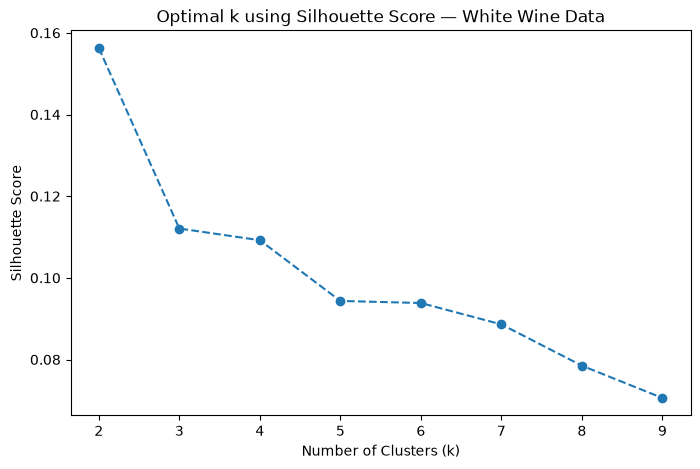

In [30]:
# Reusing the previously calculated k values and silhouette scores
K = white_k_values_agglomerative
silhouette_scores = white_coeff_values
plot_silhouette_scores('White Wine Data', K, silhouette_scores)

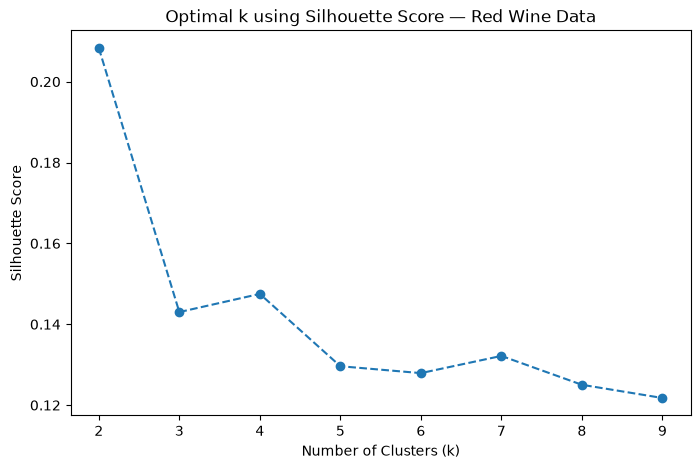

In [31]:
K = red_k_values_agglomerative
silhouette_scores = red_coeff_values
plot_silhouette_scores('Red Wine Data', K, silhouette_scores)

**Mohammed Grech 17/10/2026**: Among the tested values (k=2 to 9), k=2 gives the highest silhouette score for hierarchical clustering on both datasets: approximately 0.156 for white wine and 0.208 for red wine. These relatively low scores suggest weak separation between the clusters, with some overlap. Many wines have similar characteristics even when assigned to different clusters.